# 07 - Data Transformation
**Goal:** walk through the `DataTransformation` component ([data_transformation.py](../app/components/data_transformation.py)) and test its design choices.

What the component does:
1. Reads the **validated** train and test CSVs.
2. Splits features from the target and maps the target `-1 -> 0`.
3. Builds a `Pipeline` with a `KNNImputer`, **fits on train only**, transforms train and test.
4. Saves `train.npy` / `test.npy` (target as the last column) and the fitted imputer (`.pkl`).

> Input: `train.csv` / `test.csv` from notebook 01, used as if they were the validated files. The component runs inside `Artifacts/notebooks/transform_run/`, so it cannot touch your real `Artifacts/` or `final_model/`.

In [1]:
import os, sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer, SimpleImputer

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
SRC = ROOT / "Artifacts" / "notebooks"
WORK = SRC / "transform_run"; WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)   # the component writes relative paths (Artifacts/..., final_model/...) -> they land here

from app.components.data_transformation import DataTransformation
from app.entity.config_entity import DataTransformationConfig, TrainingPipelineConfig
from app.entity.artifact_entity import DataValidationArtifact
from app.constants import training_pipeline as tp

sns.set_theme(style="whitegrid")
train = pd.read_csv(SRC / "train.csv")
test = pd.read_csv(SRC / "test.csv")
TARGET = tp.TARGET_COLUMN
print("train:", train.shape, "| test:", test.shape, "| target column:", TARGET)
print("imputer params from constants:", tp.DATA_TRANSFORMATION_IMPUTE_PARAMS)

train: (8844, 31) | test: (2211, 31) | target column: Result
imputer params from constants: {'missing_values': nan, 'n_neighbors': 3, 'weights': 'uniform'}


## 1. Features and target
The component drops `Result` from the features and maps the target `-1 -> 0`.

In [2]:
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])
y_before = train[TARGET]
y_train = train[TARGET].replace(-1, 0)
y_test = test[TARGET].replace(-1, 0)
print("before:", y_before.value_counts().to_dict())
print("after: ", y_train.value_counts().to_dict())

before: {1: 4926, -1: 3918}
after:  {1: 4926, 0: 3918}


> **Reading the output:** TBD

## 2. Missing values in this dataset

In [3]:
print("missing values - train:", int(X_train.isna().sum().sum()), "| test:", int(X_test.isna().sum().sum()))
print("distinct values across all features:", sorted(np.unique(X_train.to_numpy())))

missing values - train: 0 | test: 0
distinct values across all features: [np.int64(-1), np.int64(0), np.int64(1)]


> **Reading the output:** TBD

## 3. Does the KNN imputer fit this data? (experiment)
Since the data has no gaps, we **hide 5% of cells** in train on purpose, let each imputer fill them, and score it against the known true values. We compare:
- `KNNImputer` with different `n_neighbors` / `weights` (the pipeline uses 3, uniform)
- `SimpleImputer(most_frequent)` as a simple baseline

Score = share of hidden cells filled with exactly the right value (KNN averages are rounded to the nearest of -1/0/1 for this score).

In [4]:
rng = np.random.RandomState(42)
truth = X_train.to_numpy(dtype=float)
mask = rng.rand(*truth.shape) < 0.05
masked = truth.copy(); masked[mask] = np.nan
print(f"hidden cells: {int(mask.sum()):,} of {truth.size:,} ({mask.mean():.1%})")

def snap(a): return np.clip(np.round(a), -1, 1)       # nearest valid code

rows = []
def score(name, imputer):
    filled = imputer.fit_transform(masked)
    got, want = filled[mask], truth[mask]
    rows.append({"imputer": name,
                 "exact_match_%": 100 * (snap(got) == want).mean(),
                 "mean_abs_error": np.abs(got - want).mean(),
                 "non_integer_%": 100 * (np.abs(got - np.round(got)) > 1e-9).mean()})

score("most_frequent (baseline)", SimpleImputer(strategy="most_frequent"))
for k in [1, 3, 5, 10, 20]:
    for w in ["uniform", "distance"]:
        score(f"KNN k={k} {w}", KNNImputer(n_neighbors=k, weights=w))

imp_results = pd.DataFrame(rows).set_index("imputer")
imp_results.round(2)

hidden cells: 13,058 of 265,320 (4.9%)


,exact_match_%,mean_abs_error,non_integer_%
imputer,,,
most_frequent (baseline),74.51,0.43,0.00
KNN k=1 uniform,88.64,0.19,0.00
KNN k=1 distance,88.64,0.19,0.00
KNN k=3 uniform,78.43,0.23,23.15
KNN k=3 distance,83.44,0.19,15.19
KNN k=5 uniform,81.28,0.26,34.29
KNN k=5 distance,84.97,0.19,19.38
KNN k=10 uniform,76.31,0.29,45.34
KNN k=10 distance,83.71,0.20,23.69


> **Reading the output:** TBD

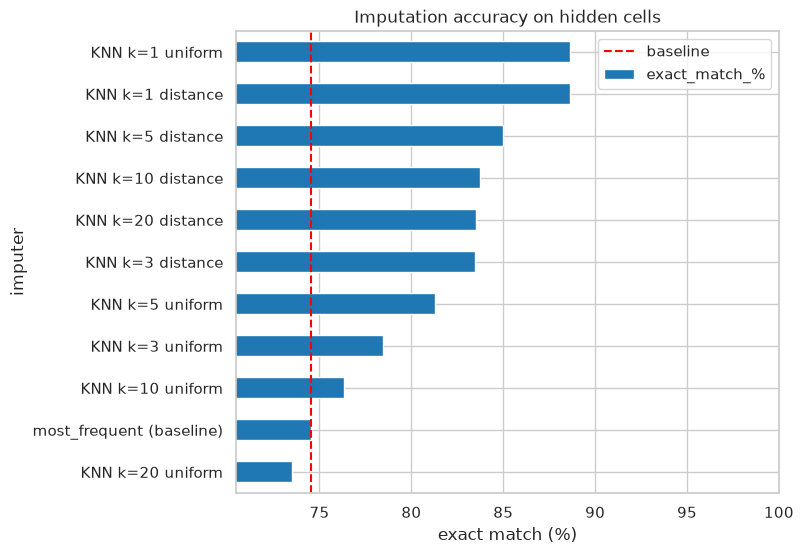

In [5]:
imp_results["exact_match_%"].sort_values().plot(kind="barh", figsize=(7, 6), color="tab:blue")
plt.axvline(imp_results.loc["most_frequent (baseline)", "exact_match_%"], color="red", ls="--", label="baseline")
plt.xlabel("exact match (%)"); plt.xlim(imp_results["exact_match_%"].min() - 3, 100)
plt.title("Imputation accuracy on hidden cells"); plt.legend(); plt.show()

> **Reading the output:** TBD

## 4. The pipeline's own transformer
Build it the way the component does and fit on **train only**. The test set is transformed with the train-fitted object, so nothing from test leaks in.

In [6]:
vartifact = DataValidationArtifact(validation_status=True,
                                   valid_train_file_path=SRC / "train.csv", valid_test_file_path=SRC / "test.csv",
                                   drift_report_file_path=SRC / "train.csv", drift_html_report_file_path=SRC / "train.csv")
tcfg = DataTransformationConfig(training_pipeline_config=TrainingPipelineConfig(timestamp="transform_nb"))
component = DataTransformation(data_validation_artifact=vartifact, data_transformation_config=tcfg)

preprocessor = component.get_data_transformer_object()
print(preprocessor)
fitted = preprocessor.fit(X_train)
Xt_train, Xt_test = fitted.transform(X_train), fitted.transform(X_test)
print("unchanged when there are no gaps -> train:", np.array_equal(Xt_train, X_train.to_numpy()),
      "| test:", np.array_equal(Xt_test, X_test.to_numpy()))

[ 2026-11-18 16:45:15.181 ] INFO     [ipykernel_launcher] app.components.data_transformation:get_data_transformer_object:50 - Initiatlize KNN imputer with {'missing_values': nan, 'n_neighbors': 3, 'weights': 'uniform'}


Pipeline(steps=[('imputer', KNNImputer(n_neighbors=3))])
unchanged when there are no gaps -> train: True | test: True


> **Reading the output:** TBD

## 5. Build the output arrays
Features plus the target as the **last column**, exactly like the component.

In [7]:
train_arr = np.c_[Xt_train, np.array(y_train)]
test_arr = np.c_[Xt_test, np.array(y_test)]
print("train_arr:", train_arr.shape, "| test_arr:", test_arr.shape)
print("last column is the target:", sorted(np.unique(train_arr[:, -1])), "| dtype:", train_arr.dtype)

train_arr: (8844, 31) | test_arr: (2211, 31)
last column is the target: [np.float64(0.0), np.float64(1.0)] | dtype: float64


> **Reading the output:** TBD

## 6. Run the real component
The same call `main.py` makes.

In [8]:
returned = component.initiate_data_transformation()
print("returned object type:", type(returned).__name__)
for p in sorted(Path("Artifacts").rglob("*")):
    if p.is_file(): print(f"{str(p):<75} {p.stat().st_size:>9,} bytes")
print("final_model/:", [str(p) for p in Path("final_model").iterdir()])

[ 2026-11-18 16:45:15.212 ] INFO     [ipykernel_launcher] app.components.data_transformation:initiate_data_transformation:60 - Performing the data transformation
[ 2026-11-18 16:45:15.227 ] INFO     [ipykernel_launcher] app.components.data_transformation:get_data_transformer_object:50 - Initiatlize KNN imputer with {'missing_values': nan, 'n_neighbors': 3, 'weights': 'uniform'}
[ 2026-11-18 16:45:15.244 ] INFO     [ipykernel_launcher] app.components.data_transformation:initiate_data_transformation:88 - Saving the transformed training and test data and Imputer object.


returned object type: DataTranformationArtifact
Artifacts/transform_nb/data_transformation/transformed/test.npy               548,456 bytes
Artifacts/transform_nb/data_transformation/transformed/train.npy            2,193,440 bytes
Artifacts/transform_nb/data_transformation/transformed_object/preprocessing.pkl 2,389,428 bytes
final_model/: ['final_model/preprocessor.pkl']


> **Reading the output:** TBD

In [9]:
saved_train = np.load(tcfg.transformed_train_file_path)
saved_test = np.load(tcfg.transformed_test_file_path)
print("saved train.npy equals our array:", np.array_equal(saved_train, train_arr))
print("saved test.npy equals our array: ", np.array_equal(saved_test, test_arr))

saved train.npy equals our array: True
saved test.npy equals our array:  True


> **Reading the output:** TBD

## 7. Use the saved imputer at prediction time
A new site arrives with one feature unknown (`NaN`). The saved preprocessor fills it using the training data.

In [10]:
loaded = joblib.load(tcfg.transformed_object_file_path)
sample = X_test.head(3).astype(float).copy()
sample.iloc[0, sample.columns.get_loc("SSLfinal_State")] = np.nan
sample.iloc[1, sample.columns.get_loc("URL_of_Anchor")] = np.nan
out = pd.DataFrame(loaded.transform(sample), columns=sample.columns, index=sample.index)
print("true SSLfinal_State (row 0):", X_test.iloc[0]["SSLfinal_State"], "-> imputed:", round(out.iloc[0]["SSLfinal_State"], 3))
print("true URL_of_Anchor  (row 1):", X_test.iloc[1]["URL_of_Anchor"], "-> imputed:", round(out.iloc[1]["URL_of_Anchor"], 3))

true SSLfinal_State (row 0): 0 -> imputed: -0.333
true URL_of_Anchor  (row 1): -1 -> imputed: 0.0


> **Reading the output:** TBD

## Takeaways
TBD